In [2]:
import pandas as pd
from datasets import load_dataset
import matplotlib.pyplot as plt
import numpy as np
import ast
from adjustText import adjust_text


dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])

df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

In [15]:
df_us = df[df['job_country'] == 'United States'] 

In [16]:
df_skills = df_us.copy()
df_skills = df_skills.explode('job_skills')
skills_count = df_skills.groupby(['job_skills', 'job_title_short']).size()
df_skills_count = skills_count.reset_index(name='skill_count')
df_skills_count.sort_values(by='skill_count', ascending=False, inplace=True)



df_skills_count

,job_skills,job_title_short,skill_count
1209,python,Data Scientist,42379
1521,sql,Data Analyst,34452
1523,sql,Data Scientist,30034
455,excel,Data Analyst,27519
1243,r,Data Scientist,26022
...,...,...,...
1785,vue.js,Business Analyst,1
60,arch,Business Analyst,1
71,asana,Machine Learning Engineer,1
968,no-sql,Machine Learning Engineer,1


In [17]:
job_titles = ['Data Scientist', 'Data Engineer', 'Data Analyst']

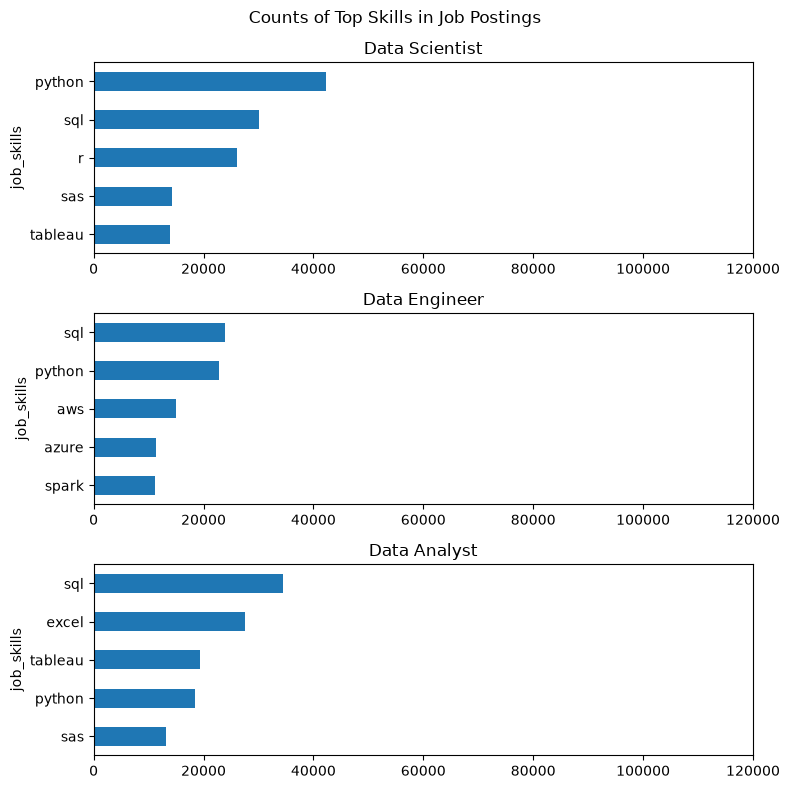

In [18]:
# job_titles = ['Data Scientist', 'Data Engineer', 'Data Analyst']

fig, ax = plt.subplots(3, 1, figsize=(8, 8))

for i, job_title in enumerate(job_titles):
    df_plot = (
        df_skills_count[df_skills_count['job_title_short'] == job_title]
        .head(5)
        .sort_values('skill_count')
    )
    df_plot.plot(
        kind='barh',
        x='job_skills',
        y='skill_count',
        ax=ax[i],
        legend=False,
        title=job_title
    )
    ax[i].set_xlim(0, 120000)

fig.suptitle('Counts of Top Skills in Job Postings')
fig.tight_layout()

In [19]:

df_us['job_title_short'].value_counts().reset_index(name='jobs_total')

,job_title_short,jobs_total
0,Data Analyst,67816
1,Data Scientist,58830
2,Data Engineer,35080
3,Senior Data Scientist,12946
4,Senior Data Analyst,11791
5,Senior Data Engineer,9289
6,Business Analyst,7382
7,Software Engineer,1814
8,Machine Learning Engineer,921
9,Cloud Engineer,423


In [20]:
df_job_title_count = df_us['job_title_short'].value_counts().reset_index(name='jobs_total')

In [21]:
pd.merge(df_skills_count, df_job_title_count, on='job_title_short')

,job_skills,job_title_short,skill_count,jobs_total
0,python,Data Scientist,42379,58830
1,sql,Data Analyst,34452,67816
2,sql,Data Scientist,30034,58830
3,excel,Data Analyst,27519,67816
4,r,Data Scientist,26022,58830
...,...,...,...,...
1865,vue.js,Business Analyst,1,7382
1866,arch,Business Analyst,1,7382
1867,asana,Machine Learning Engineer,1,921
1868,no-sql,Machine Learning Engineer,1,921


In [22]:
df_skills_perc = pd.merge(df_skills_count, df_job_title_count, on='job_title_short')

In [23]:
df_skills_perc['skill_percent'] = (100 * df_skills_perc['skill_count']) / df_skills_perc['jobs_total']

df_skills_perc

,job_skills,job_title_short,skill_count,jobs_total,skill_percent
0,python,Data Scientist,42379,58830,72.036376
1,sql,Data Analyst,34452,67816,50.802171
2,sql,Data Scientist,30034,58830,51.052184
3,excel,Data Analyst,27519,67816,40.578919
4,r,Data Scientist,26022,58830,44.232534
...,...,...,...,...,...
1865,vue.js,Business Analyst,1,7382,0.013546
1866,arch,Business Analyst,1,7382,0.013546
1867,asana,Machine Learning Engineer,1,921,0.108578
1868,no-sql,Machine Learning Engineer,1,921,0.108578


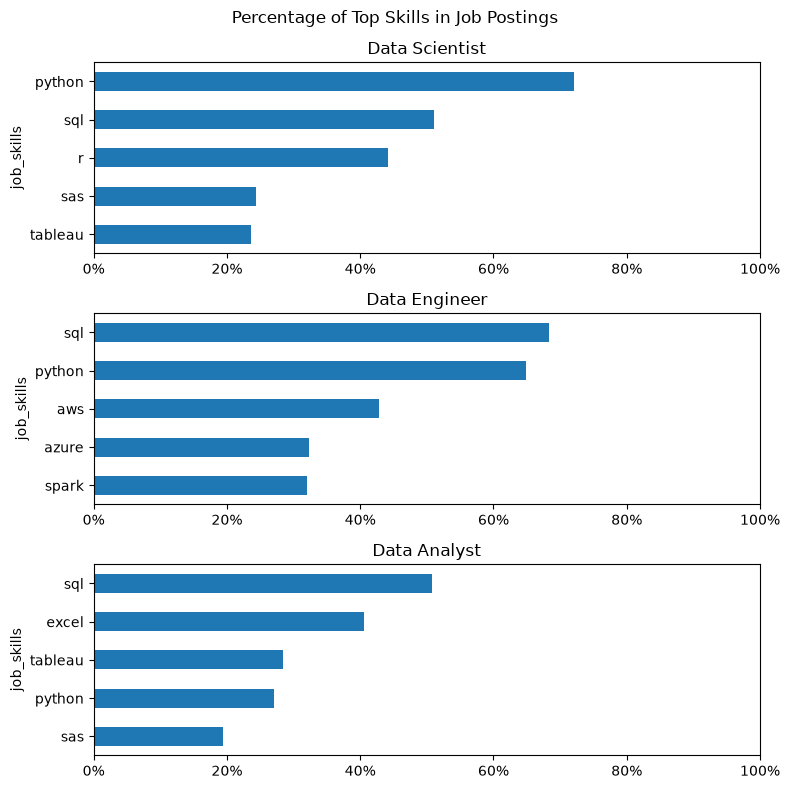

In [27]:
from matplotlib.ticker import PercentFormatter

fig, ax = plt.subplots(3, 1, figsize=(8, 8))

for i, job_title in enumerate(job_titles):
    df_plot = (
        df_skills_perc[df_skills_perc['job_title_short'] == job_title]
        .head(5)
        .sort_values('skill_count')
    )

    df_plot.plot(
        kind='barh',
        x='job_skills',
        y='skill_percent',
        ax=ax[i],
        legend=False,
        title=job_title
    )

    ax[i].set_xlim(0, 100)
    ax[i].xaxis.set_major_formatter(PercentFormatter(100))

fig.suptitle('Percentage of Top Skills in Job Postings')
fig.tight_layout()

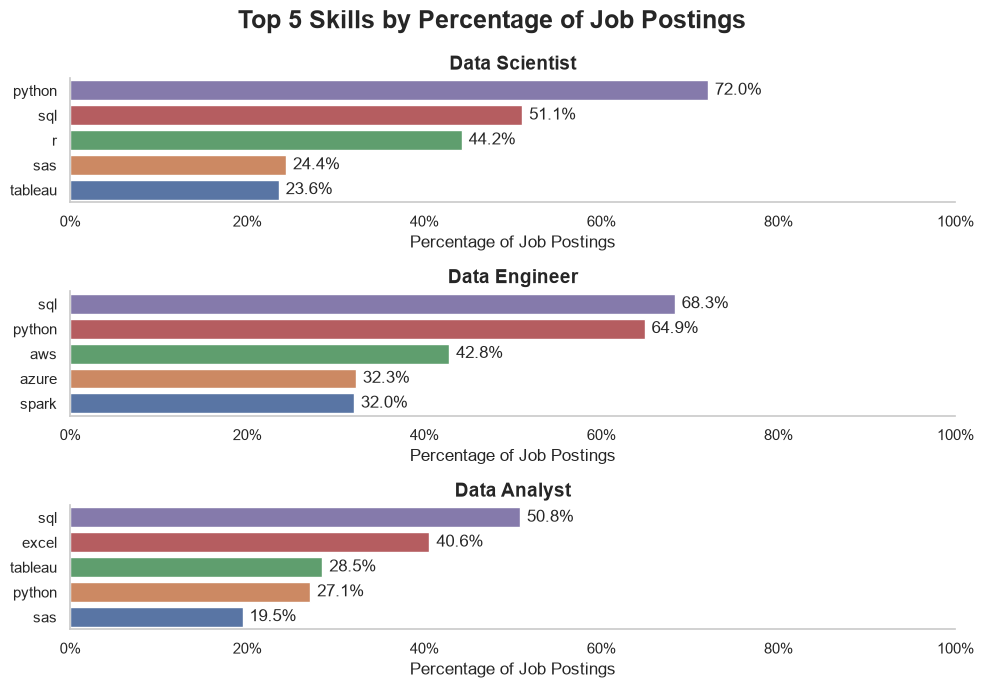

In [40]:
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

sns.set_theme(style="whitegrid")

fig, ax = plt.subplots(3, 1, figsize=(10, 7))

for i, job_title in enumerate(job_titles):

    df_plot = (
        df_skills_perc[
            df_skills_perc['job_title_short'] == job_title
        ]
        .head(5)
        .sort_values('skill_percent')
    )

    sns.barplot(
        data=df_plot,
        x='skill_percent',
        y='job_skills',
        ax=ax[i],
        hue='job_skills',
        legend=False
    )

    ax[i].set_title(
        job_title,
        fontsize=14,
        fontweight='bold',
        loc='center'
    )

    ax[i].set_xlabel('Percentage of Job Postings')
    ax[i].set_ylabel('')
    ax[i].invert_yaxis()
    ax[i].grid(axis='x', visible=False)

    ax[i].set_xlim(0, 100)
    ax[i].xaxis.set_major_formatter(PercentFormatter(100))

    # Add percentage labels to bars
    for container in ax[i].containers:
        ax[i].bar_label(
            container,
            fmt='%.1f%%',
            padding=5
        )

sns.despine()

fig.suptitle(
    'Top 5 Skills by Percentage of Job Postings',
    fontsize=18,
    fontweight='bold'
)

fig.tight_layout()
plt.show()